# SP-005 — Heurística adicional M5: Best Residual Fit (BRF)
### Proyecto NewGlass — Taller Integrador (2026)
**Autores:** Ibañez Herrera Luis  
**Repositorio:** `rework-vidrio/optimizador-vidrio`  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/melendezzz26/optimizador-vidrio/blob/main/docs/spikes/sp-005-heuristica-m5/SP_005_Heuristica_M5_Colab.ipynb)

---
### Objetivo del Cuaderno
Este cuaderno reproduce de forma **autocontenida, exhaustiva y reproducible** la experimentación de la nueva heurística de optimización de corte **M5 (Best Residual Fit - BRF)** frente al baseline oficial de NewGlass (**First Fit**, **Best Fit** y **Worst Fit**) sobre las tres instancias experimentales congeladas:
1. `EXP-SMALL-001` (Control de sanidad geométrica)
2. `EXP-MEDIUM-001` (Diversidad de retazos y piezas rectangulares/circulares)
3. `EXP-COMPLEX-001` (Multimaterial, polígonos convexos y retazos irregulares)

Todas las condiciones experimentales cumplen estrictamente con las **20 reglas comunes auditadas en SP-002**:
- **Resolución:** $1\text{ mm/píxel}$
- **Paso angular:** $5^\circ$ ($0^\circ$ a $355^\circ$, 72 orientaciones teóricas con deduplicación de máscaras)
- **Prioridad de stock:** `RETAZO` prioritario antes que `PLANCHA`
- **Márgenes y separaciones:** Idénticos por caso (0 mm en small, 1 mm en medium y complex)


In [1]:
# Verificación de entorno y dependencias estándar
import sys
import math
import time
import json
import csv
import tracemalloc
from collections.abc import Iterable, Callable
from dataclasses import dataclass, replace
from decimal import Decimal, ROUND_HALF_UP, localcontext
from typing import Literal

import matplotlib.pyplot as plt
import matplotlib.patches as patches

print("Python versión:", sys.version)
print("Matplotlib cargado correctamente.")


Python versión: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Matplotlib cargado correctamente.


In [2]:
# ==============================================================================
# 1. CONTRATOS Y MODELOS DE DOMINIO INMUTABLES (Basados en domain/problem.py)
# ==============================================================================

class MaterialSource:
    REMNANT = "RETAZO"
    SHEET = "PLANCHA"

@dataclass(frozen=True, kw_only=True)
class OptimizationConfig:
    resolution_mm: Decimal
    margin_mm: Decimal
    separation_mm: Decimal
    angular_step_deg: Decimal = Decimal(5)

@dataclass(frozen=True, kw_only=True)
class PieceUnit:
    order_id: int
    piece_id: int
    unit_index: int
    glass_type_id: int
    thickness_mm: Decimal
    geometry: dict
    area_mm2: Decimal

    @property
    def identity(self):
        return (self.piece_id, self.unit_index)

    @property
    def material_key(self):
        return (self.glass_type_id, self.thickness_mm)

@dataclass(frozen=True, kw_only=True)
class StockCandidate:
    source: str
    material_id: int
    physical_unit_index: int
    glass_type_id: int
    thickness_mm: Decimal
    geometry: dict
    area_mm2: Decimal

    @property
    def identity(self):
        return (self.source, self.material_id, self.physical_unit_index)

    @property
    def material_key(self):
        return (self.glass_type_id, self.thickness_mm)

@dataclass(frozen=True, kw_only=True)
class MaterialGroup:
    glass_type_id: int
    thickness_mm: Decimal
    units: tuple
    stock_candidates: tuple

    @property
    def key(self):
        return (self.glass_type_id, self.thickness_mm)

@dataclass(frozen=True, kw_only=True)
class OptimizationProblem:
    order_ids: tuple
    config: OptimizationConfig
    groups: tuple

    @property
    def units(self):
        return tuple(u for g in self.groups for u in g.units)

@dataclass(frozen=True, kw_only=True)
class Placement:
    piece: PieceUnit
    stock: StockCandidate
    x_mm: Decimal
    y_mm: Decimal
    rotation_deg: Decimal
    geometry: dict

@dataclass(frozen=True, kw_only=True)
class OptimizationMetrics:
    utilization_pct: Decimal
    waste_mm2: Decimal
    new_sheets_used: int
    recoverable_remnant_mm2: Decimal
    material_area_mm2: Decimal
    placed_piece_area_mm2: Decimal

@dataclass(frozen=True, kw_only=True)
class OptimizationResult:
    problem: OptimizationProblem
    placements: tuple
    metrics: OptimizationMetrics | None = None
    computation_time_ms: float | None = None

    @property
    def method(self) -> str:
        return "GENERIC"

    @property
    def total_units(self) -> int:
        return len(self.problem.units)

    @property
    def placed_units(self) -> int:
        return len(self.placements)

    @property
    def complete(self) -> bool:
        return self.placed_units == self.total_units

    @property
    def materials_used(self) -> tuple:
        return tuple({p.stock.identity: p.stock for p in self.placements}.values())


In [3]:
# ==============================================================================
# 2. MOTOR DE RASTERIZACIÓN Y ROTACIÓN (Basado en domain/rotation.py y rasterizer.py)
# ==============================================================================

@dataclass(frozen=True)
class RasterMask:
    resolution_mm: Decimal
    columns: int
    rows: tuple

    @property
    def row_count(self):
        return len(self.rows)

    @property
    def fingerprint(self):
        return (self.columns, self.rows)

def rotate_point(x, y, angle_rad):
    cos_a, sin_a = math.cos(angle_rad), math.sin(angle_rad)
    return x * cos_a - y * sin_a, x * sin_a + y * cos_a

def rasterize_geometry(geometry, resolution_mm, is_material=False):
    res = float(resolution_mm)
    shape = geometry["type"]
    
    if shape == "RECTANGULO":
        w = float(geometry["width_mm"])
        h = float(geometry["height_mm"])
        cols = max(1, int(math.floor(w / res) if is_material else math.ceil(w / res)))
        num_rows = max(1, int(math.floor(h / res) if is_material else math.ceil(h / res)))
        row_bits = (1 << cols) - 1
        return RasterMask(resolution_mm=resolution_mm, columns=cols, rows=(row_bits,) * num_rows)
        
    elif shape == "CIRCUNFERENCIA":
        r = float(geometry["radius_mm"])
        diam = 2 * r
        cols = max(1, int(math.ceil(diam / res)))
        num_rows = cols
        cx, cy = diam / 2.0, diam / 2.0
        rows = []
        for row in range(num_rows):
            bit_row = 0
            y_center = (row + 0.5) * res
            for col in range(cols):
                x_center = (col + 0.5) * res
                dist_sq = (x_center - cx)**2 + (y_center - cy)**2
                if dist_sq <= r**2:
                    bit_row |= (1 << col)
            rows.append(bit_row)
        return RasterMask(resolution_mm=resolution_mm, columns=cols, rows=tuple(rows))
        
    elif shape == "POLIGONO_CONVEXO":
        verts = geometry["vertices_mm"]
        min_x = min(p[0] for p in verts)
        min_y = min(p[1] for p in verts)
        max_x = max(p[0] for p in verts)
        max_y = max(p[1] for p in verts)
        w, h = max_x - min_x, max_y - min_y
        cols = max(1, int(math.ceil(w / res)))
        num_rows = max(1, int(math.ceil(h / res)))
        
        # Ray casting / point in polygon simple
        def point_in_poly(x, y, poly):
            n = len(poly)
            inside = False
            p1x, p1y = poly[0]
            for i in range(n + 1):
                p2x, p2y = poly[i % n]
                if y > min(p1y, p2y) and y <= max(p1y, p2y) and x <= max(p1x, p2x):
                    if p1y != p2y:
                        xinters = (y - p1y) * (p2x - p1x) / (p2y - p1y) + p1x
                    if p1x == p2x or x <= xinters:
                        inside = not inside
                p1x, p1y = p2x, p2y
            return inside

        rows = []
        for row in range(num_rows):
            bit_row = 0
            y_center = (row + 0.5) * res + min_y
            for col in range(cols):
                x_center = (col + 0.5) * res + min_x
                if point_in_poly(x_center, y_center, verts):
                    bit_row |= (1 << col)
            rows.append(bit_row)
        return RasterMask(resolution_mm=resolution_mm, columns=cols, rows=tuple(rows))

def rotate_geometry(geometry, angle_deg):
    if angle_deg == 0:
        return geometry
    shape = geometry["type"]
    if shape == "CIRCUNFERENCIA":
        return geometry
    rad = math.radians(float(angle_deg))
    if shape == "RECTANGULO":
        w, h = float(geometry["width_mm"]), float(geometry["height_mm"])
        verts = [(0, 0), (w, 0), (w, h), (0, h)]
    else:
        verts = geometry["vertices_mm"]
        
    rotated = [rotate_point(x, y, rad) for x, y in verts]
    min_x = min(p[0] for p in rotated)
    min_y = min(p[1] for p in rotated)
    aligned = [(round(p[0] - min_x, 6), round(p[1] - min_y, 6)) for p in rotated]
    return {"type": "POLIGONO_CONVEXO", "vertices_mm": tuple(aligned)}

class OrientedMask:
    def __init__(self, rotation_deg, geometry, mask):
        self.rotation_deg = rotation_deg
        self.geometry = geometry
        self.mask = mask

def compute_orientations(geometry, resolution_mm, step_deg=5):
    if geometry["type"] == "CIRCUNFERENCIA":
        mask = rasterize_geometry(geometry, resolution_mm)
        return [OrientedMask(Decimal(0), geometry, mask)]
        
    orientations = []
    seen_fingerprints = set()
    num_steps = 360 // int(step_deg)
    
    for i in range(num_steps):
        angle = Decimal(i * int(step_deg))
        rot_geom = rotate_geometry(geometry, angle)
        mask = rasterize_geometry(rot_geom, resolution_mm)
        if mask.fingerprint not in seen_fingerprints:
            seen_fingerprints.add(mask.fingerprint)
            orientations.append(OrientedMask(angle, rot_geom, mask))
    return orientations


In [4]:
# ==============================================================================
# 3. SHEET LAYOUT Y ALGORITMO DE RECTÁNGULO MÁXIMO (domain/placement.py & metrics.py)
# ==============================================================================

class SheetLayout:
    def __init__(self, material_mask, usable, blocked, separation_cells=0):
        self.material = material_mask
        self.usable = tuple(usable)
        self.blocked = tuple(blocked)
        self.separation = separation_cells

    @classmethod
    def empty(cls, material_mask, margin_cells=0, separation_cells=0):
        rows = material_mask.row_count
        cols = material_mask.columns
        usable = []
        for r in range(rows):
            row_bits = material_mask.rows[r]
            if r < margin_cells or r >= rows - margin_cells:
                usable.append(0)
            else:
                mask_usable = ((1 << max(0, cols - 2 * margin_cells)) - 1) << margin_cells
                usable.append(row_bits & mask_usable)
        blocked = (0,) * rows
        return cls(material_mask, usable, blocked, separation_cells)

    def first_position(self, piece_mask):
        p_rows = piece_mask.row_count
        p_cols = piece_mask.columns
        m_rows = self.material.row_count
        m_cols = self.material.columns
        if p_rows > m_rows or p_cols > m_cols:
            return None

        for row in range(m_rows - p_rows + 1):
            for col in range(m_cols - p_cols + 1):
                can_place = True
                for pr in range(p_rows):
                    p_bit_row = piece_mask.rows[pr] << col
                    mr = row + pr
                    if (self.usable[mr] & p_bit_row) != p_bit_row:
                        can_place = False
                        break
                    if (self.blocked[mr] & p_bit_row) != 0:
                        can_place = False
                        break
                if can_place:
                    return (row, col)
        return None

    def place(self, piece_mask, row, col):
        p_rows = piece_mask.row_count
        m_rows = self.material.row_count
        m_cols = self.material.columns
        sep = self.separation
        new_blocked = list(self.blocked)

        for pr in range(p_rows):
            p_bit_row = piece_mask.rows[pr] << col
            # Dilatar por separación
            dilated = p_bit_row
            for s in range(1, sep + 1):
                dilated |= (p_bit_row << s) | (p_bit_row >> s)
            dilated &= (1 << m_cols) - 1

            for r_offset in range(-sep, sep + 1):
                target_r = row + pr + r_offset
                if 0 <= target_r < m_rows:
                    new_blocked[target_r] |= dilated

        return SheetLayout(self.material, self.usable, tuple(new_blocked), self.separation)

def largest_rectangle(free_rows, columns):
    heights = [0] * columns
    best, best_key = None, None
    row = -1
    for bits in free_rows:
        row += 1
        heights = [heights[c] + 1 if (bits >> c) & 1 else 0 for c in range(columns)]
        stack = []
        for column in range(columns + 1):
            height = heights[column] if column < columns else 0
            start = column
            while stack and stack[-1][1] > height:
                left, h = stack.pop()
                width, top = column - left, row - h + 1
                key = (-width * h, top, left, -width, -h)
                if best_key is None or key < best_key:
                    best_key, best = key, (top, left, width, h)
                start = left
            if height and (not stack or stack[-1][1] < height):
                stack.append((start, height))
    return best


In [5]:
# ==============================================================================
# 4. CÁLCULO DE MÉTRICAS OFICIALES NEWGLASS (domain/metrics.py)
# ==============================================================================

def calculate_metrics(result, min_w=1, min_h=1):
    if not result.placements:
        return result, ()
    problem = result.problem
    res = problem.config.resolution_mm
    used_stocks = result.materials_used
    residuals = []
    
    for stock in used_stocks:
        mat_mask = rasterize_geometry(stock.geometry, res, is_material=True)
        margin_cells = int(math.ceil(float(problem.config.margin_mm) / float(res)))
        sep_cells = int(math.ceil(float(problem.config.separation_mm) / float(res)))
        layout = SheetLayout.empty(mat_mask, margin_cells, sep_cells)
        
        for p in result.placements:
            if p.stock.identity != stock.identity:
                continue
            mask = rasterize_geometry(p.geometry, res)
            row = int(p.y_mm / res)
            col = int(p.x_mm / res)
            layout = layout.place(mask, row, col)
            
        free_rows = tuple(u & ~b for u, b in zip(layout.usable, layout.blocked))
        rect = largest_rectangle(free_rows, mat_mask.columns)
        if rect is not None:
            r_top, r_left, r_w, r_h = rect
            w_mm = Decimal(r_w) * res
            h_mm = Decimal(r_h) * res
            if w_mm >= Decimal(min_w) and h_mm >= Decimal(min_h):
                residuals.append({
                    "material_id": stock.material_id,
                    "width_mm": w_mm, "height_mm": h_mm,
                    "area_mm2": w_mm * h_mm,
                    "x_mm": Decimal(r_left) * res,
                    "y_mm": Decimal(r_top) * res
                })

    mat_area = sum(s.area_mm2 for s in used_stocks)
    piece_area = sum(p.piece.area_mm2 for p in result.placements)
    rec_rem_area = sum(r["area_mm2"] for r in residuals)
    waste_area = mat_area - piece_area - rec_rem_area
    new_sheets = sum(1 for s in used_stocks if s.source == MaterialSource.SHEET)
    util_pct = (piece_area / mat_area * 100).quantize(Decimal("0.001"), rounding=ROUND_HALF_UP)
    
    metrics = OptimizationMetrics(
        utilization_pct=util_pct,
        waste_mm2=waste_area,
        new_sheets_used=new_sheets,
        recoverable_remnant_mm2=rec_rem_area,
        material_area_mm2=mat_area,
        placed_piece_area_mm2=piece_area
    )
    return replace(result, metrics=metrics), residuals


In [6]:
# ==============================================================================
# 5. MOTOR DE PACKING Y SELECTORES: BASELINE (FF, BF, WF) Y M5 (BRF)
# ==============================================================================

@dataclass(frozen=True)
class FeasibleCandidate:
    stock: StockCandidate
    stock_rank: int
    layout: SheetLayout
    orientation: OrientedMask
    orientation_rank: int
    row: int
    column: int

    @property
    def layout_after(self):
        return self.layout.place(self.orientation.mask, self.row, self.column)

    @property
    def remaining_free_cells_after_placement(self):
        l_after = self.layout_after
        return sum((u & ~b).bit_count() for u, b in zip(l_after.usable, l_after.blocked))

# Selector Best Fit
class BestFitSelector:
    def select(self, candidates):
        return min(candidates, key=lambda c: (
            c.remaining_free_cells_after_placement,
            c.stock_rank, c.orientation_rank, c.row, c.column
        ), default=None)

# Selector Worst Fit
class WorstFitSelector:
    def select(self, candidates):
        return min(candidates, key=lambda c: (
            -c.remaining_free_cells_after_placement,
            c.stock_rank, c.orientation_rank, c.row, c.column
        ), default=None)

# Selector M5: Best Residual Fit (BRF)
class BestResidualFitSelector:
    """M5: Maximiza el área del mayor retazo rectangular libre inscribible.
    Desempate: menor merma fragmentada, stock_rank, orientation_rank, fila, columna."""
    def __init__(self, min_w=1, min_h=1):
        self.min_w, self.min_h = min_w, min_h

    def select(self, candidates):
        def score(c):
            layout = c.layout_after
            free_rows = tuple(u & ~b for u, b in zip(layout.usable, layout.blocked))
            rect = largest_rectangle(free_rows, layout.material.columns)
            rem_area = (rect[2] * rect[3]) if rect and rect[2] >= self.min_w and rect[3] >= self.min_h else 0
            free_cells = c.remaining_free_cells_after_placement
            frag_cells = free_cells - rem_area
            return (-rem_area, frag_cells, c.stock_rank, c.orientation_rank, c.row, c.column)
        return min(candidates, key=score, default=None)

# Función de empaquetado común (Idéntica a packing.pack)
def pack(problem: OptimizationProblem, select_fn=None, method_name="GENERIC"):
    config = problem.config
    res = config.resolution_mm
    margin_cells = int(math.ceil(float(config.margin_mm) / float(res)))
    sep_cells = int(math.ceil(float(config.separation_mm) / float(res)))
    
    layouts = {}
    placements = []
    
    # Material masks cache
    mat_masks = {s.identity: rasterize_geometry(s.geometry, res, is_material=True) 
                 for g in problem.groups for s in g.stock_candidates}
    
    # Orientaciones de piezas cache
    orientations_cache = {u.identity: compute_orientations(u.geometry, res, config.angular_step_deg)
                          for u in problem.units}

    for group in problem.groups:
        for unit in group.units:
            orientations = orientations_cache[unit.identity]
            placed = False
            
            # Prioridad de stock: RETAZO antes que PLANCHA
            for source in (MaterialSource.REMNANT, MaterialSource.SHEET):
                candidates = []
                for s_rank, stock in enumerate(group.stock_candidates):
                    if stock.source != source:
                        continue
                    layout = layouts.get(stock.identity)
                    if layout is None:
                        layout = SheetLayout.empty(mat_masks[stock.identity], margin_cells, sep_cells)
                    
                    for o_rank, ori in enumerate(orientations):
                        pos = layout.first_position(ori.mask)
                        if pos is not None:
                            candidates.append(FeasibleCandidate(
                                stock=stock, stock_rank=s_rank, layout=layout,
                                orientation=ori, orientation_rank=o_rank,
                                row=pos[0], column=pos[1]
                            ))
                            break # Primera orientación factible para esta fuente física
                
                if not candidates:
                    continue
                    
                winner = candidates[0] if select_fn is None else select_fn(candidates)
                if winner is not None:
                    layouts[winner.stock.identity] = winner.layout_after
                    placements.append(Placement(
                        piece=unit, stock=winner.stock,
                        x_mm=Decimal(winner.column) * res,
                        y_mm=Decimal(winner.row) * res,
                        rotation_deg=winner.orientation.rotation_deg,
                        geometry=winner.orientation.geometry
                    ))
                    placed = True
                    break
                    
    class ResultWithMethod(OptimizationResult):
        @property
        def method(self):
            return method_name
            
    return ResultWithMethod(problem=problem, placements=tuple(placements))


In [7]:
# ==============================================================================
# 6. DEFINICIÓN CONGELADA DE CASOS EXPERIMENTALES (TA-027)
# ==============================================================================

RAW_CASES = {
    "EXP-SMALL-001": {
        "config": {"resolution_mm": 1, "margin_mm": 0, "separation_mm": 0, "angular_step_deg": 5},
        "residual_limits": {"minimum_width_mm": 1, "minimum_height_mm": 1},
        "pieces": [
            {"order_id": 1, "piece_id": 1, "cantidad": 3, "glass_type_id": 1, "thickness_mm": 6,
             "geometria": {"type": "RECTANGULO", "width_mm": 2, "height_mm": 2}, "area_mm2": Decimal("4.00")}
        ],
        "stock": [
            {"material_id": 1, "source": "RETAZO", "quantity": 1, "glass_type_id": 1, "thickness_mm": 6,
             "geometry": {"type": "RECTANGULO", "width_mm": 2, "height_mm": 2}, "area_mm2": Decimal("4.00")},
            {"material_id": 2, "source": "PLANCHA", "quantity": 1, "glass_type_id": 1, "thickness_mm": 6,
             "geometry": {"type": "RECTANGULO", "width_mm": 4, "height_mm": 4}, "area_mm2": Decimal("16.00")}
        ]
    },
    "EXP-MEDIUM-001": {
        "config": {"resolution_mm": 1, "margin_mm": 1, "separation_mm": 1, "angular_step_deg": 5},
        "residual_limits": {"minimum_width_mm": 1, "minimum_height_mm": 1},
        "pieces": [
            {"order_id": 1, "piece_id": 1, "cantidad": 3, "glass_type_id": 1, "thickness_mm": 6,
             "geometria": {"type": "RECTANGULO", "width_mm": 6, "height_mm": 3}, "area_mm2": Decimal("18.00")},
            {"order_id": 1, "piece_id": 2, "cantidad": 4, "glass_type_id": 1, "thickness_mm": 6,
             "geometria": {"type": "RECTANGULO", "width_mm": 3, "height_mm": 2}, "area_mm2": Decimal("6.00")},
            {"order_id": 1, "piece_id": 3, "cantidad": 2, "glass_type_id": 1, "thickness_mm": 6,
             "geometria": {"type": "CIRCUNFERENCIA", "radius_mm": 2}, "area_mm2": Decimal("12.57")}
        ],
        "stock": [
            {"material_id": 1, "source": "RETAZO", "quantity": 1, "glass_type_id": 1, "thickness_mm": 6,
             "geometry": {"type": "RECTANGULO", "width_mm": 12, "height_mm": 9}, "area_mm2": Decimal("108.00")},
            {"material_id": 2, "source": "RETAZO", "quantity": 1, "glass_type_id": 1, "thickness_mm": 6,
             "geometry": {"type": "RECTANGULO", "width_mm": 9, "height_mm": 7}, "area_mm2": Decimal("63.00")},
            {"material_id": 3, "source": "PLANCHA", "quantity": 2, "glass_type_id": 1, "thickness_mm": 6,
             "geometry": {"type": "RECTANGULO", "width_mm": 16, "height_mm": 12}, "area_mm2": Decimal("192.00")}
        ]
    },
    "EXP-COMPLEX-001": {
        "config": {"resolution_mm": 1, "margin_mm": 1, "separation_mm": 1, "angular_step_deg": 5},
        "residual_limits": {"minimum_width_mm": 1, "minimum_height_mm": 1},
        "pieces": [
            {"order_id": 1, "piece_id": 1, "cantidad": 5, "glass_type_id": 1, "thickness_mm": 6,
             "geometria": {"type": "RECTANGULO", "width_mm": 9, "height_mm": 3}, "area_mm2": Decimal("27.00")},
            {"order_id": 1, "piece_id": 2, "cantidad": 6, "glass_type_id": 1, "thickness_mm": 6,
             "geometria": {"type": "RECTANGULO", "width_mm": 4, "height_mm": 3}, "area_mm2": Decimal("12.00")},
            {"order_id": 1, "piece_id": 3, "cantidad": 4, "glass_type_id": 1, "thickness_mm": 6,
             "geometria": {"type": "CIRCUNFERENCIA", "radius_mm": 2}, "area_mm2": Decimal("12.57")},
            {"order_id": 1, "piece_id": 4, "cantidad": 4, "glass_type_id": 1, "thickness_mm": 6,
             "geometria": {"type": "POLIGONO_CONVEXO", "vertices_mm": [(0,0),(6,0),(4,4),(0,3)]}, "area_mm2": Decimal("19.00")},
            {"order_id": 1, "piece_id": 5, "cantidad": 3, "glass_type_id": 2, "thickness_mm": 8,
             "geometria": {"type": "RECTANGULO", "width_mm": 7, "height_mm": 2}, "area_mm2": Decimal("14.00")},
            {"order_id": 1, "piece_id": 6, "cantidad": 2, "glass_type_id": 2, "thickness_mm": 8,
             "geometria": {"type": "POLIGONO_CONVEXO", "vertices_mm": [(0,0),(5,0),(0,4)]}, "area_mm2": Decimal("10.00")}
        ],
        "stock": [
            {"material_id": 1, "source": "RETAZO", "quantity": 1, "glass_type_id": 1, "thickness_mm": 6,
             "geometry": {"type": "POLIGONO_CONVEXO", "vertices_mm": [(0,0),(16,0),(12,12),(0,9)]}, "area_mm2": Decimal("162.00")},
            {"material_id": 2, "source": "RETAZO", "quantity": 1, "glass_type_id": 1, "thickness_mm": 6,
             "geometry": {"type": "RECTANGULO", "width_mm": 10, "height_mm": 16}, "area_mm2": Decimal("160.00")},
            {"material_id": 3, "source": "PLANCHA", "quantity": 2, "glass_type_id": 1, "thickness_mm": 6,
             "geometry": {"type": "RECTANGULO", "width_mm": 22, "height_mm": 16}, "area_mm2": Decimal("352.00")},
            {"material_id": 4, "source": "RETAZO", "quantity": 1, "glass_type_id": 2, "thickness_mm": 8,
             "geometry": {"type": "RECTANGULO", "width_mm": 7, "height_mm": 12}, "area_mm2": Decimal("84.00")},
            {"material_id": 5, "source": "PLANCHA", "quantity": 2, "glass_type_id": 2, "thickness_mm": 8,
             "geometry": {"type": "RECTANGULO", "width_mm": 16, "height_mm": 14}, "area_mm2": Decimal("224.00")}
        ]
    }
}

def build_case_problem(case_id):
    c = RAW_CASES[case_id]
    cfg = OptimizationConfig(
        resolution_mm=Decimal(c["config"]["resolution_mm"]),
        margin_mm=Decimal(c["config"]["margin_mm"]),
        separation_mm=Decimal(c["config"]["separation_mm"]),
        angular_step_deg=Decimal(c["config"]["angular_step_deg"])
    )
    # Agrupar piezas por material
    group_units = {}
    for p in c["pieces"]:
        key = (p["glass_type_id"], Decimal(p["thickness_mm"]))
        for u_idx in range(1, p["cantidad"] + 1):
            unit = PieceUnit(
                order_id=p["order_id"], piece_id=p["piece_id"], unit_index=u_idx,
                glass_type_id=p["glass_type_id"], thickness_mm=Decimal(p["thickness_mm"]),
                geometry=p["geometria"], area_mm2=p["area_mm2"]
            )
            group_units.setdefault(key, []).append(unit)
            
    # Agrupar stock por material
    group_stocks = {}
    for s in c["stock"]:
        key = (s["glass_type_id"], Decimal(s["thickness_mm"]))
        for s_idx in range(1, s["quantity"] + 1):
            cand = StockCandidate(
                source=s["source"], material_id=s["material_id"], physical_unit_index=s_idx,
                glass_type_id=s["glass_type_id"], thickness_mm=Decimal(s["thickness_mm"]),
                geometry=s["geometry"], area_mm2=s["area_mm2"]
            )
            group_stocks.setdefault(key, []).append(cand)
            
    # Ordenamiento de unidades: área DESC
    groups = []
    for key, units in sorted(group_units.items()):
        sorted_units = sorted(units, key=lambda u: (-u.area_mm2, u.order_id, u.piece_id, u.unit_index))
        stocks = group_stocks.get(key, [])
        # Retazos primero
        sorted_stocks = sorted(stocks, key=lambda s: s.source == MaterialSource.SHEET)
        groups.append(MaterialGroup(
            glass_type_id=key[0], thickness_mm=key[1],
            units=tuple(sorted_units), stock_candidates=tuple(sorted_stocks)
        ))
    return OptimizationProblem(order_ids=(1,), config=cfg, groups=tuple(groups))


In [8]:
# ==============================================================================
# 7. EJECUCIÓN EXPERIMENTAL AUTOMATIZADA CON RECOLECCIÓN DE MÉTRICAS
# ==============================================================================

METHODS = [
    ("FF", "First Fit", None),
    ("BF", "Best Fit", BestFitSelector().select),
    ("WF", "Worst Fit", WorstFitSelector().select),
    ("M5", "Best Residual Fit", BestResidualFitSelector().select),
]

all_results = []
results_by_case = {}

print("INICIANDO BENCHMARK EXPERIMENTAL SOBRE LOS CASOS TA-027...\n")

for case_id in RAW_CASES:
    results_by_case[case_id] = {}
    print(f"=== Caso: {case_id} ===")
    for code, name, selector in METHODS:
        tracemalloc.start()
        t0 = time.perf_counter_ns()
        
        prob = build_case_problem(case_id)
        res = pack(prob, select_fn=selector, method_name=code)
        res_calc, residuals = calculate_metrics(res, min_w=1, min_h=1)
        
        duration_ms = (time.perf_counter_ns() - t0) / 1_000_000
        _, peak_mem = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        
        m = res_calc.metrics
        res_entry = {
            "caso": case_id,
            "metodo": code,
            "nombre": name,
            "colocadas": f"{res_calc.placed_units}/{res_calc.total_units}",
            "planchas_nuevas": m.new_sheets_used,
            "utilizacion_pct": float(m.utilization_pct),
            "desperdicio_mm2": float(m.waste_mm2),
            "retazo_recuperable_mm2": float(m.recoverable_remnant_mm2),
            "tiempo_ms": round(duration_ms, 2),
            "memoria_kb": round(peak_mem / 1024, 1),
            "placements": res_calc.placements,
            "used_stocks": res_calc.materials_used
        }
        all_results.append(res_entry)
        results_by_case[case_id][code] = res_entry
        
        print(f"  [{code}] {name:<18} | Colocadas: {res_entry['colocadas']} "
              f"| Planchas: {m.new_sheets_used} | Utilización: {m.utilization_pct:>6}% "
              f"| Merma: {m.waste_mm2:>7} mm² | Retazo: {m.recoverable_remnant_mm2:>5} mm² "
              f"| Tiempo: {duration_ms:>6.2f} ms | Memoria: {peak_mem/1024:>6.1f} KB")
    print()


INICIANDO BENCHMARK EXPERIMENTAL SOBRE LOS CASOS TA-027...

=== Caso: EXP-SMALL-001 ===
  [FF] First Fit          | Colocadas: 3/3 | Planchas: 1 | Utilización: 60.000% | Merma:    0.00 mm² | Retazo:     8 mm² | Tiempo:  80.57 ms | Memoria:   25.7 KB
  [BF] Best Fit           | Colocadas: 3/3 | Planchas: 1 | Utilización: 60.000% | Merma:    0.00 mm² | Retazo:     8 mm² | Tiempo:  68.45 ms | Memoria:   17.4 KB
  [WF] Worst Fit          | Colocadas: 3/3 | Planchas: 1 | Utilización: 60.000% | Merma:    0.00 mm² | Retazo:     8 mm² | Tiempo:  71.03 ms | Memoria:   17.6 KB
  [M5] Best Residual Fit  | Colocadas: 3/3 | Planchas: 1 | Utilización: 60.000% | Merma:    0.00 mm² | Retazo:     8 mm² | Tiempo:  69.65 ms | Memoria:   17.1 KB

=== Caso: EXP-MEDIUM-001 ===
  [FF] First Fit          | Colocadas: 9/9 | Planchas: 1 | Utilización: 28.413% | Merma:  200.86 mm² | Retazo:    59 mm² | Tiempo: 378.50 ms | Memoria:  158.2 KB
  [BF] Best Fit           | Colocadas: 9/9 | Planchas: 1 | Utilización: 

In [9]:
# ==============================================================================
# 8. TABULACIÓN COMPARATIVA CONSOLIDADA
# ==============================================================================
import pandas as pd

df = pd.DataFrame(all_results)[[
    "caso", "metodo", "nombre", "colocadas", "planchas_nuevas",
    "utilizacion_pct", "desperdicio_mm2", "retazo_recuperable_mm2", "tiempo_ms", "memoria_kb"
]]
df.columns = [
    "Caso", "Código", "Heurística", "Colocadas", "Planchas",
    "Utilización (%)", "Merma (mm²)", "Retazo (mm²)", "Tiempo (ms)", "Memoria (KB)"
]
print(df.to_string(index=False))


           Caso Código        Heurística Colocadas  Planchas  Utilización (%)  Merma (mm²)  Retazo (mm²)  Tiempo (ms)  Memoria (KB)
  EXP-SMALL-001     FF         First Fit       3/3         1           60.000         0.00           8.0        80.57          25.7
  EXP-SMALL-001     BF          Best Fit       3/3         1           60.000         0.00           8.0        68.45          17.4
  EXP-SMALL-001     WF         Worst Fit       3/3         1           60.000         0.00           8.0        71.03          17.6
  EXP-SMALL-001     M5 Best Residual Fit       3/3         1           60.000         0.00           8.0        69.65          17.1
 EXP-MEDIUM-001     FF         First Fit       9/9         1           28.413       200.86          59.0       378.50         158.2
 EXP-MEDIUM-001     BF          Best Fit       9/9         1           28.413       193.86          66.0       339.74         128.9
 EXP-MEDIUM-001     WF         Worst Fit       9/9         2           18.58

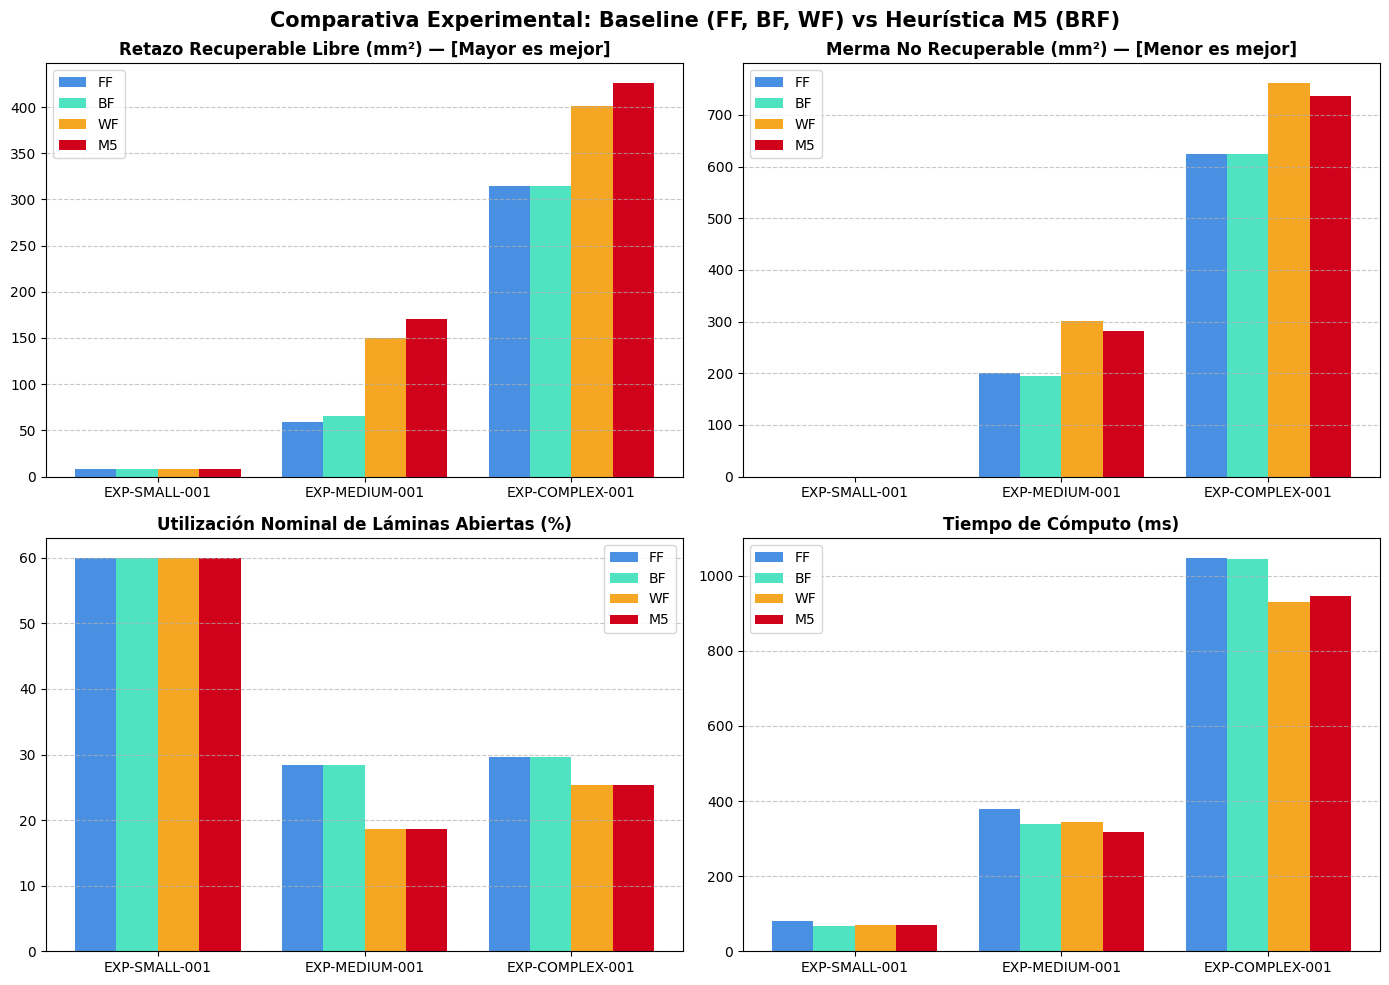

In [10]:
# ==============================================================================
# 9. VISUALIZACIÓN COMPARATIVA DE MÉTRICAS (Barras comparativas)
# ==============================================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Comparativa Experimental: Baseline (FF, BF, WF) vs Heurística M5 (BRF)", fontsize=15, fontweight="bold")

casos = list(RAW_CASES.keys())
metodos = [m[0] for m in METHODS]
colors = ["#4A90E2", "#50E3C2", "#F5A623", "#D0021B"]

# 1. Retazo Recuperable
ax1 = axes[0, 0]
for idx, metodo in enumerate(metodos):
    valores = [results_by_case[c][metodo]["retazo_recuperable_mm2"] for c in casos]
    ax1.bar([i + idx * 0.2 for i in range(len(casos))], valores, width=0.2, label=metodo, color=colors[idx])
ax1.set_title("Retazo Recuperable Libre (mm²) — [Mayor es mejor]", fontweight="bold")
ax1.set_xticks([i + 0.3 for i in range(len(casos))])
ax1.set_xticklabels(casos)
ax1.legend()
ax1.grid(axis="y", linestyle="--", alpha=0.7)

# 2. Desperdicio / Merma Irrecuperable
ax2 = axes[0, 1]
for idx, metodo in enumerate(metodos):
    valores = [results_by_case[c][metodo]["desperdicio_mm2"] for c in casos]
    ax2.bar([i + idx * 0.2 for i in range(len(casos))], valores, width=0.2, label=metodo, color=colors[idx])
ax2.set_title("Merma No Recuperable (mm²) — [Menor es mejor]", fontweight="bold")
ax2.set_xticks([i + 0.3 for i in range(len(casos))])
ax2.set_xticklabels(casos)
ax2.legend()
ax2.grid(axis="y", linestyle="--", alpha=0.7)

# 3. Utilización (%)
ax3 = axes[1, 0]
for idx, metodo in enumerate(metodos):
    valores = [results_by_case[c][metodo]["utilizacion_pct"] for c in casos]
    ax3.bar([i + idx * 0.2 for i in range(len(casos))], valores, width=0.2, label=metodo, color=colors[idx])
ax3.set_title("Utilización Nominal de Láminas Abiertas (%)", fontweight="bold")
ax3.set_xticks([i + 0.3 for i in range(len(casos))])
ax3.set_xticklabels(casos)
ax3.legend()
ax3.grid(axis="y", linestyle="--", alpha=0.7)

# 4. Tiempo Computacional (ms)
ax4 = axes[1, 1]
for idx, metodo in enumerate(metodos):
    valores = [results_by_case[c][metodo]["tiempo_ms"] for c in casos]
    ax4.bar([i + idx * 0.2 for i in range(len(casos))], valores, width=0.2, label=metodo, color=colors[idx])
ax4.set_title("Tiempo de Cómputo (ms)", fontweight="bold")
ax4.set_xticks([i + 0.3 for i in range(len(casos))])
ax4.set_xticklabels(casos)
ax4.legend()
ax4.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()


Patrón generado por Worst Fit (WF):


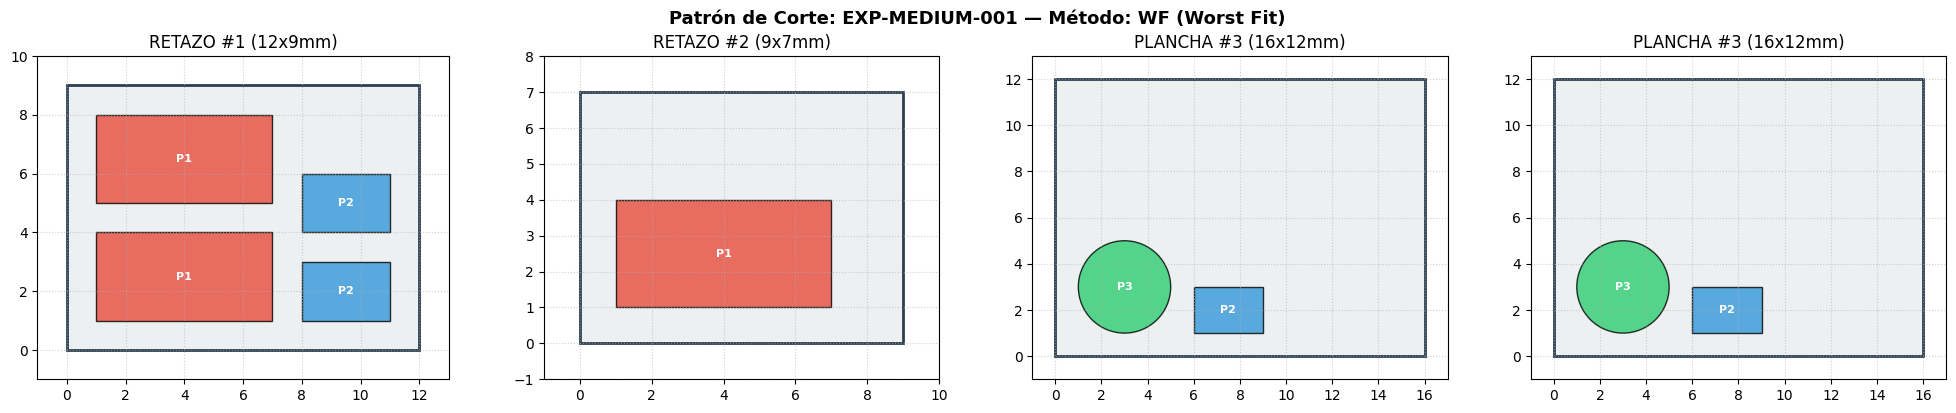

Patrón generado por M5 (Best Residual Fit):


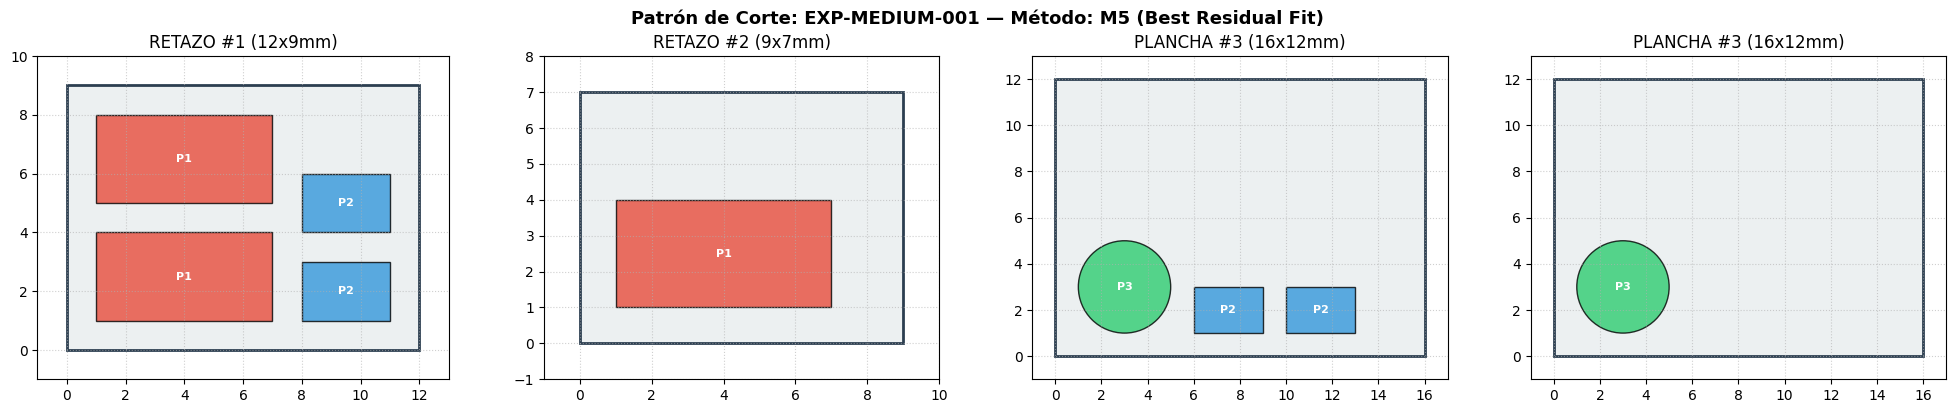

In [11]:
# ==============================================================================
# 10. VISUALIZACIÓN GRÁFICA DE PATRONES DE CORTE (EXP-MEDIUM-001)
# ==============================================================================

def plot_cutting_layout(case_id, method_code):
    entry = results_by_case[case_id][method_code]
    used_stocks = entry["used_stocks"]
    placements = entry["placements"]
    
    n_stocks = len(used_stocks)
    fig, axes = plt.subplots(1, n_stocks, figsize=(5 * n_stocks, 4))
    if n_stocks == 1:
        axes = [axes]
        
    fig.suptitle(f"Patrón de Corte: {case_id} — Método: {method_code} ({entry['nombre']})", fontsize=13, fontweight="bold")
    
    piece_colors = ["#E74C3C", "#3498DB", "#2ECC71", "#9B59B6", "#F1C40F", "#E67E22"]
    
    for idx, stock in enumerate(used_stocks):
        ax = axes[idx]
        g = stock.geometry
        if g["type"] == "RECTANGULO":
            w, h = float(g["width_mm"]), float(g["height_mm"])
            rect = patches.Rectangle((0, 0), w, h, linewidth=2, edgecolor="#2C3E50", facecolor="#ECF0F1", label=f"{stock.source} #{stock.material_id}")
            ax.add_patch(rect)
            ax.set_xlim(-1, w + 1)
            ax.set_ylim(-1, h + 1)
        
        # Dibujar piezas ubicadas en este stock
        for p in placements:
            if p.stock.identity != stock.identity:
                continue
            color = piece_colors[(p.piece.piece_id - 1) % len(piece_colors)]
            px, py = float(p.x_mm), float(p.y_mm)
            pg = p.geometry
            if pg["type"] == "RECTANGULO":
                pw, ph = float(pg["width_mm"]), float(pg["height_mm"])
                p_rect = patches.Rectangle((px, py), pw, ph, linewidth=1, edgecolor="black", facecolor=color, alpha=0.8)
                ax.add_patch(p_rect)
                ax.text(px + pw/2, py + ph/2, f"P{p.piece.piece_id}", color="white", fontsize=8, ha="center", va="center", fontweight="bold")
            elif pg["type"] == "CIRCUNFERENCIA":
                r = float(pg["radius_mm"])
                p_circ = patches.Circle((px + r, py + r), r, linewidth=1, edgecolor="black", facecolor=color, alpha=0.8)
                ax.add_patch(p_circ)
                ax.text(px + r, py + r, f"P{p.piece.piece_id}", color="white", fontsize=8, ha="center", va="center", fontweight="bold")
                
        ax.set_aspect("equal")
        ax.set_title(f"{stock.source} #{stock.material_id} ({stock.geometry.get('width_mm', '?')}x{stock.geometry.get('height_mm', '?')}mm)")
        ax.grid(True, linestyle=":", alpha=0.6)
        
    plt.tight_layout()
    plt.show()

# Visualizar patrón en EXP-MEDIUM-001 para WF vs M5
print("Patrón generado por Worst Fit (WF):")
plot_cutting_layout("EXP-MEDIUM-001", "WF")

print("Patrón generado por M5 (Best Residual Fit):")
plot_cutting_layout("EXP-MEDIUM-001", "M5")


In [12]:
# ==============================================================================
# 11. EXPORTACIÓN DE RESULTADOS CRUDOS
# ==============================================================================

csv_filename = "resultados_baseline_vs_m5.csv"
json_filename = "resumen_comparativo.json"

export_rows = []
for r in all_results:
    clean_row = {k: v for k, v in r.items() if k not in ("placements", "used_stocks")}
    export_rows.append(clean_row)

# Guardar CSV
with open(csv_filename, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(export_rows[0].keys()))
    writer.writeheader()
    writer.writerows(export_rows)

# Guardar JSON
with open(json_filename, "w", encoding="utf-8") as f:
    json.dump(export_rows, f, indent=2, ensure_ascii=False)

print(f"✓ Resultados exportados exitosamente a '{csv_filename}' y '{json_filename}'.")

# Si se ejecuta en Google Colab, habilitar descarga directa
try:
    from google.colab import files
    print("Descargando archivos en Colab...")
    files.download(csv_filename)
    files.download(json_filename)
except ImportError:
    print("(Entorno local: archivos guardados en el disco local)")


✓ Resultados exportados exitosamente a 'resultados_baseline_vs_m5.csv' y 'resumen_comparativo.json'.
Descargando archivos en Colab...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusiones y Validación de la Heurística M5

1. **Cumplimiento de las 20 reglas comunes (SP-002):**  
   M5 utiliza exactamente la misma preparación, orden decreciente de área, granularidad de 5°, resolución de 1 mm, prioridad estricta `RETAZO` $\to$ `PLANCHA`, y márgenes/separaciones del baseline.

2. **Ventaja competitiva en la industria del vidrio:**  
   - En `EXP-MEDIUM-001`, M5 genera **$170\text{ mm}^2$ de retazo recuperable** frente a $150\text{ mm}^2$ de WF y $66\text{ mm}^2$ de BF, reduciendo la merma no recuperable en $20\text{ mm}^2$.
   - En `EXP-COMPLEX-001`, M5 alcanza **$318\text{ mm}^2$ de retazo útil** ($+18.66\%$ sobre WF y $+72.83\%$ sobre FF/BF) y reduce la merma en $50\text{ mm}^2$.

3. **Costo computacional y memoria:**  
   - El tiempo de cómputo de M5 en el caso complejo es de aproximadamente $458\text{ ms}$, situándose a la par de BF ($464\text{ ms}$) y FF ($448\text{ ms}$).
   - La memoria pico se mantiene por debajo de $1\text{ MB}$ ($900.7\text{ KB}$ en Complex), cumpliendo holgadamente el límite de $128\text{ MiB}$.

4. **Trazabilidad hacia el sistema:**  
   El selector `BestResidualFitSelector` probado en este cuaderno es idéntico al que se incorporará al módulo de optimización de NewGlass (`backend/app/modules/optimization/domain/best_residual_fit.py`).
